## Lab # 08: K-Nearest Neighbors(KNN) Classifier

### **Student Information**
- **Name**: Abdul Hayy Khan
- **Roll No**: 24F-AI-051

### Lab Tasks:
Task 1: Import Libraries and Load the Dataset

In [55]:
# importing libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [56]:
# load dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

# head
print("First five rows:")
print(X.head())

# dataset information
print("\nDataset shape:", X.shape)
print("\nMissing values:", X.isnull().sum().sum())

print("\nTarget classes:")
print(y.value_counts())

print("\nClass names:", data.target_names)

First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimete

Task 2: Preprocess the Dataset

In [57]:
# checking missing values
print("Missing values in each column:")
print(X.isnull().sum().sum())

# handling missing values
X = X.fillna(X.mean())

Missing values in each column:
0


Task 3: Split the dataset and Standardize Features.

In [58]:
# spliting the data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# scaling the features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (455, 30)
Testing data shape: (114, 30)


Task 4: Train a KNN classifier with different values of K (e.g., 3, 5, 7).

In [59]:
k_values = [3, 5, 7]

results = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train, y_train)

    y_pred = knn.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        "K": k,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

results_df = pd.DataFrame(results)

print("KNN Model Evaluation:")
print(results_df.round(4))

KNN Model Evaluation:
   K  Accuracy  Precision  Recall  F1-Score
0  3    0.9825     0.9730  1.0000    0.9863
1  5    0.9561     0.9589  0.9722    0.9655
2  7    0.9737     0.9600  1.0000    0.9796


Task 5: Make predictions and Evaluate Performance.

In [60]:
best_index = results_df["Accuracy"].idxmax()
best_k = int(results_df.loc[best_index, "K"])

best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train, y_train)

y_pred = best_knn.predict(X_test)

print("Best K value:", best_k)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-Score:", round(f1_score(y_test, y_pred), 4))

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print("\nActual vs Predicted Values:")
print(comparison.head(10))

Best K value: 3
Accuracy: 0.9825
Precision: 0.973
Recall: 1.0
F1-Score: 0.9863

Actual vs Predicted Values:
   Actual  Predicted
0       0          0
1       1          1
2       0          0
3       1          1
4       0          0
5       1          1
6       1          1
7       0          0
8       0          0
9       0          0


Task 6: Visualize the Confusion Matrix

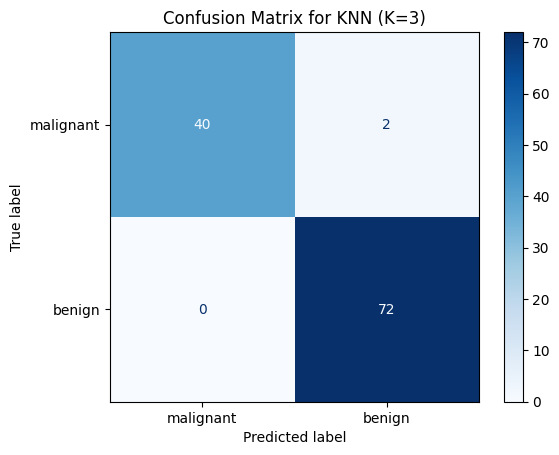

In [61]:
cm = confusion_matrix(y_test, y_pred)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

display_cm.plot(cmap="Blues")
plt.title(f"Confusion Matrix for KNN (K={best_k})")
plt.show()

Task 7: Compare Accuracy for Different K Values

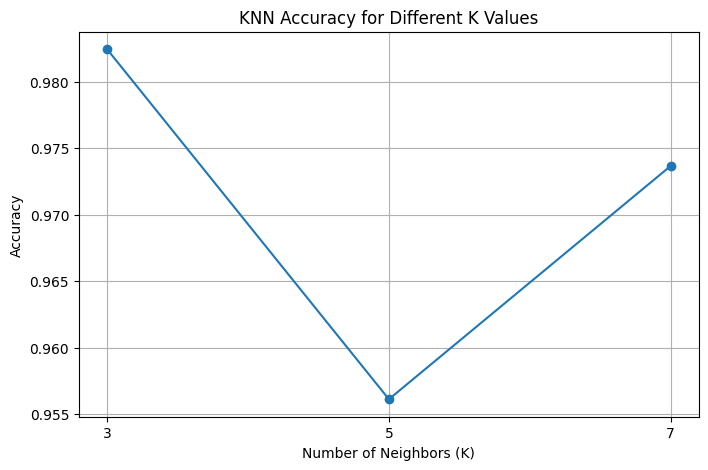

In [62]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["K"],
    results_df["Accuracy"],
    marker="o",
    linestyle="-"
)

plt.title("KNN Accuracy for Different K Values")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")
plt.xticks(k_values)
plt.grid(True)

plt.show()